# PCA (EOF) analysis of NCEP/NCAR surface air temperature over North America
Mathematical Foundation for AI, FAST-NUCES Karachi
Jahan Zaib (26K-7626) and Kariz Kamal (24K-9014)

Data: NCEP/NCAR Reanalysis 1 from NOAA PSL. On Kaggle, turn Internet on so the data can be downloaded.

**What this notebook does.** It applies principal component analysis (PCA, called EOF analysis in climate science) to daily near-surface air temperature over North America (NCEP/NCAR Reanalysis 1, 2013-2014, 1325 grid points). It produces every table, figure and number used in the project report. Run all cells from top to bottom.

In [1]:
# Imports, plot style, folders and a helper that finds the data file (local copy, Kaggle input, or download)
import json
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})

DATA_DIR = Path("data")
FIG_DIR = Path("outputs/figures")
TAB_DIR = Path("outputs/tables")
for d in (DATA_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

NC_URL = "https://raw.githubusercontent.com/pydata/xarray-data/master/air_temperature.nc"
GEO_URL = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json"

def get_file(name, url):
    local = DATA_DIR / name
    if local.exists():
        return local
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        hits = list(kaggle_input.glob(f"**/{name}"))
        if hits:
            return hits[0]
    print(f"Downloading {name} ...")
    urllib.request.urlretrieve(url, local)
    return local

## 1. Load the data

The four-times-daily file (2920 maps) is read, converted from kelvin to degC and averaged to daily means. This gives n = 730 days (rows) and p = 1325 grid points (columns). `w` holds the area weights sqrt(cos(latitude)).

In [2]:
# Load the data, convert to degC, average the four daily values, build the area weights
ds = xr.open_dataset(get_file("air_temperature.nc", NC_URL))
T = (ds["air"] - 273.15).resample(time="1D").mean()
lat, lon = T["lat"].values, T["lon"].values
time = pd.to_datetime(T["time"].values)
n, ny, nx = T.shape
p = ny * nx
field = T.values
print(f"days n = {n}, grid points p = {p}, missing values = {int(np.isnan(field).sum())}")

w = np.sqrt(np.cos(np.deg2rad(lat)))[:, None] * np.ones((1, nx))

clim_mean = field.mean(axis=0)
day = np.arange(n)
omega = 2 * np.pi / 365.25

days n = 730, grid points p = 1325, missing values = 0


## 2. PCA functions

`eof_analysis` weights the data, removes the time mean and uses the SVD: eigenvalues = s^2/(n-1), EOFs = right singular vectors, PCs = U*S. The other helpers compute the lag-1 autocorrelation, the effective sample size (for North's rule and significance tests), regression maps in degC per standard deviation of a PC, and area-mean time series of a box.

In [3]:
# PCA functions: SVD-based EOF analysis and small helpers used in the later sections
def eof_analysis(F, weights=w):
    nt = F.shape[0]
    X = (F * weights).reshape(nt, -1)
    X = X - X.mean(axis=0)
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    eigvals = S ** 2 / (nt - 1)
    pcs = U * S
    for k in range(len(S)):
        if Vt[k][np.argmax(np.abs(Vt[k]))] < 0:
            Vt[k] *= -1
            pcs[:, k] *= -1
    return eigvals, pcs, Vt

def lag1(x):
    return np.corrcoef(x[:-1], x[1:])[0, 1]

def n_eff(r1x, r1y=None):
    if r1y is None:
        return n * (1 - r1x) / (1 + r1x)
    return n * (1 - r1x * r1y) / (1 + r1x * r1y)

def regression_maps(anom, z, k):
    A = anom.reshape(len(anom), -1)
    A = A - A.mean(0)
    return ((z[:, :k].T @ A) / (len(A) - 1)).reshape(k, ny, nx)

def box_mean(anom, lat_rng, lon_rng):
    la = (lat >= lat_rng[0]) & (lat <= lat_rng[1])
    lo = (lon >= lon_rng[0]) & (lon <= lon_rng[1])
    ww = np.cos(np.deg2rad(lat[la]))[:, None] * np.ones((1, lo.sum()))
    return (anom[:, la][:, :, lo] * ww).sum((1, 2)) / ww.sum()

## 3. Analysis A: full field

**Analysis A** is PCA of the full field (seasonal cycle kept). The first mode is expected to be the annual cycle; we confirm this by correlating PC1 with a fitted annual harmonic.

In [4]:
# Analysis A: PCA of the full field; check that PC1 follows the annual cycle
lamA, pcA, eofA = eof_analysis(field)
if np.corrcoef(pcA[:, 0], np.cos(omega * (day - 200)))[0, 1] < 0:
    pcA[:, 0] *= -1
    eofA[0] *= -1
varA = 100 * lamA / lamA.sum()
zA = pcA / pcA.std(axis=0, ddof=1)
regA = regression_maps(field, zA, 3)

H1 = np.column_stack([np.ones(n), np.cos(omega * day), np.sin(omega * day)])
coef, *_ = np.linalg.lstsq(H1, zA[:, 0], rcond=None)
fit1 = H1 @ coef
R_annual = np.corrcoef(fit1, zA[:, 0])[0, 1]
peak_doy = int(np.argmax(fit1[:366]) + 1)
print("Analysis A: variance explained (%) of PC1-5:", np.round(varA[:5], 2))
print(f"  PC1 vs annual harmonic: R = {R_annual:.3f}; fitted maximum on day-of-year {peak_doy}")

Analysis A: variance explained (%) of PC1-5: [80.7   2.62  2.39  1.95  1.39]
  PC1 vs annual harmonic: R = 0.991; fitted maximum on day-of-year 208


## 4. Analysis B: anomalies

**Analysis B** removes the seasonal cycle first (mean + annual + semi-annual harmonics, fitted by least squares at every grid point, because two years are too short for a day-by-day climatology) and then repeats the PCA on the anomalies.

In [5]:
# Analysis B: remove mean + annual + semi-annual harmonics, then PCA of the anomalies
H = np.column_stack([np.ones(n)] + [f(k * omega * day) for k in (1, 2) for f in (np.cos, np.sin)])
beta, *_ = np.linalg.lstsq(H, field.reshape(n, -1), rcond=None)
seasonal = (H @ beta).reshape(n, ny, nx)
anom = field - seasonal

wvar_full = ((field - field.mean(0)) ** 2 * w ** 2).sum() / (n - 1)
wvar_anom = ((anom - anom.mean(0)) ** 2 * w ** 2).sum() / (n - 1)
seasonal_share = 100 * (1 - wvar_anom / wvar_full)
print(f"Seasonal cycle (annual+semi-annual harmonics) explains {seasonal_share:.1f}% of the total variance")

lamB, pcB, eofB = eof_analysis(anom)
varB = 100 * lamB / lamB.sum()
cumB = np.cumsum(varB)
zB = pcB / pcB.std(axis=0, ddof=1)
regB = regression_maps(anom, zB, 6)
print("Analysis B: variance explained (%) of PC1-10:", np.round(varB[:10], 2))
print("            cumulative (%):", np.round(cumB[:10], 1))

Seasonal cycle (annual+semi-annual harmonics) explains 82.5% of the total variance


Analysis B: variance explained (%) of PC1-10: [14.9   9.89  9.68  6.22  5.75  4.67  4.4   3.69  3.27  2.38]
            cumulative (%): [14.9 24.8 34.5 40.7 46.4 51.1 55.5 59.2 62.5 64.9]


## 5. Checks

Four checks that the PCA is correct: SVD eigenvalues match `eigvalsh` of the covariance matrix, eigenvalues sum to the trace, EOFs are orthonormal, PCs are uncorrelated. Differences should be near machine precision (about 1e-12 or smaller).

In [6]:
# Checks: SVD vs covariance eigen-decomposition, trace, orthonormality, uncorrelated PCs
Xw = (anom * w).reshape(n, -1)
Xw = Xw - Xw.mean(0)
C = Xw.T @ Xw / (n - 1)
ev_cov = np.sort(np.linalg.eigvalsh(C))[::-1]
checks = {
    "max |eigenvalue(cov) - eigenvalue(SVD)| (first 20)": float(np.max(np.abs(ev_cov[:20] - lamB[:20]))),
    "trace(C) - sum(eigenvalues)": float(np.trace(C) - lamB.sum()),
    "max |EOF.EOF^T - I| (first 10)": float(np.max(np.abs(eofB[:10] @ eofB[:10].T - np.eye(10)))),
    "max |corr(PCi,PCj)|, i!=j (first 10)": float(np.max(np.abs(np.corrcoef(pcB[:, :10].T) - np.eye(10)))),
    "number of non-zero eigenvalues": int(np.sum(lamB > 1e-10 * lamB[0])),
    "total variance (weighted degC^2)": float(lamB.sum()),
}
for k, v in checks.items():
    print(f"{k:55s} {v:.3e}" if isinstance(v, float) else f"{k:55s} {v}")

max |eigenvalue(cov) - eigenvalue(SVD)| (first 20)      2.274e-12
trace(C) - sum(eigenvalues)                             -5.457e-12
max |EOF.EOF^T - I| (first 10)                          1.110e-15
max |corr(PCi,PCj)|, i!=j (first 10)                    8.127e-16
number of non-zero eigenvalues                          725
total variance (weighted degC^2)                        9.162e+03


## 6. North's rule

North's rule: sampling error of an eigenvalue = lambda * sqrt(2 / N_eff). A mode counts as separated from the next one only if the gap between their eigenvalues is larger than the larger of the two errors. Modes that are not separated should not be interpreted one by one.

In [7]:
# North's rule: effective sample size, sampling errors and which modes are separated
K = 15
r1B = np.array([lag1(pcB[:, k]) for k in range(K)])
neffB = n_eff(r1B)
errB = lamB[:K] * np.sqrt(2 / neffB)
gap = lamB[:K - 1] - lamB[1:K]
sep = gap > np.maximum(errB[:K - 1], errB[1:K])
tblB = pd.DataFrame({
    "Mode": np.arange(1, K + 1),
    "Eigenvalue (degC^2)": lamB[:K],
    "Variance (%)": varB[:K],
    "Cumulative (%)": cumB[:K],
    "Lag-1 autocorr": r1B,
    "N_eff": neffB,
    "North error (degC^2)": errB,
    "Separated from next": list(sep) + [np.nan],
})
tblB.round(3).to_csv(TAB_DIR / "table_eigenvalues_anomaly_PCA.csv", index=False)
print(tblB.round(3).head(8).to_string(index=False))

r1A = np.array([lag1(pcA[:, k]) for k in range(10)])
tblA = pd.DataFrame({"Mode": np.arange(1, 11), "Eigenvalue (degC^2)": lamA[:10], "Variance (%)": varA[:10],
                     "Cumulative (%)": np.cumsum(varA[:10]), "Lag-1 autocorr": r1A})
tblA.round(3).to_csv(TAB_DIR / "table_eigenvalues_full_field_PCA.csv", index=False)

 Mode  Eigenvalue (degC^2)  Variance (%)  Cumulative (%)  Lag-1 autocorr   N_eff  North error (degC^2) Separated from next
    1             1365.084        14.900          14.900           0.903  37.375               315.778                True
    2              906.426         9.894          24.794           0.778  91.014               134.367               False
    3              886.600         9.677          34.471           0.872  49.760               177.746                True
    4              569.936         6.221          40.692           0.875  48.596               115.622               False
    5              526.492         5.747          46.439           0.760  99.564                74.620                True
    6              427.954         4.671          51.110           0.811  76.306                69.284               False
    7              403.524         4.405          55.514           0.746 106.314                55.346                True
    8           

## 7. Regional correlations

Each of the first four PCs is correlated with the area-mean anomaly of seven regions. Significance uses a two-sided t-test at the 5 % level with the effective sample size of the pair of series.

In [8]:
# Correlate PC1-PC4 with seven regional temperature series (5 % significance test)
regions = {
    "Alaska / NW Canada (60-70N, 155-125W)": ((60, 70), (205, 235)),
    "Western USA (32-45N, 125-110W)": ((32, 45), (235, 250)),
    "Central USA / Plains (35-47.5N, 105-92W)": ((35, 47.5), (255, 268)),
    "Eastern USA / Gt Lakes (35-47.5N, 88-75W)": ((35, 47.5), (272, 285)),
    "Hudson Bay / Arctic Canada (55-70N, 95-65W)": ((55, 70), (265, 295)),
    "Greenland / N. Atlantic (60-75N, 60-30W)": ((60, 75), (300, 330)),
    "Mexico / Gulf (17.5-27.5N, 105-85W)": ((17.5, 27.5), (255, 275)),
}
rows = []
for name, (la, lo) in regions.items():
    ts = box_mean(anom, la, lo)
    row = {"Region": name}
    for k in range(4):
        r = np.corrcoef(ts, zB[:, k])[0, 1]
        ne = n_eff(lag1(ts), lag1(zB[:, k]))
        t = r * np.sqrt((ne - 2) / (1 - r ** 2))
        pval = 2 * stats.t.sf(abs(t), ne - 2)
        row[f"PC{k + 1}"] = r
        row[f"PC{k + 1} sig"] = bool(pval < 0.05)
    rows.append(row)
tblR = pd.DataFrame(rows)
tblR.round(3).to_csv(TAB_DIR / "table_region_correlations.csv", index=False)
print(tblR.round(2).to_string(index=False))

                                     Region   PC1  PC1 sig   PC2  PC2 sig   PC3  PC3 sig   PC4  PC4 sig
      Alaska / NW Canada (60-70N, 155-125W) -0.32     True  0.03    False  0.73     True -0.18    False
             Western USA (32-45N, 125-110W)  0.27     True -0.59     True -0.30     True  0.19     True
   Central USA / Plains (35-47.5N, 105-92W)  0.80     True -0.04    False -0.27     True -0.05    False
  Eastern USA / Gt Lakes (35-47.5N, 88-75W)  0.40     True  0.74     True -0.08    False -0.33     True
Hudson Bay / Arctic Canada (55-70N, 95-65W)  0.26     True  0.33     True  0.28     True  0.78     True
   Greenland / N. Atlantic (60-75N, 60-30W) -0.15    False -0.01    False -0.05    False  0.40     True
        Mexico / Gulf (17.5-27.5N, 105-85W)  0.04    False  0.49     True -0.08    False -0.18     True


## 8. Reconstruction

The anomaly maps are rebuilt from the first k modes (X_k = PCs[:, :k] @ EOFs[:k]) and the RMSE is computed for several k. We also count how many modes are needed to reach 50, 70, 80 and 90 % of the variance.

In [9]:
# Reconstruction from k modes: RMSE and number of modes for 50/70/80/90 % variance
Xanom = (anom - anom.mean(0)).reshape(n, -1)
ks = [1, 2, 3, 4, 5, 10, 20, 50, 100, 200]
rec_rows = []
for k in ks:
    Xk = (pcB[:, :k] @ eofB[:k]).reshape(n, ny, nx) / w
    rmse = np.sqrt(np.mean((Xk - (anom - anom.mean(0))) ** 2))
    rec_rows.append({"k": k, "Cumulative variance (%)": cumB[k - 1], "RMSE (degC)": rmse})
tblK = pd.DataFrame(rec_rows)
tblK.round(3).to_csv(TAB_DIR / "table_reconstruction.csv", index=False)
print(tblK.round(3).to_string(index=False))
n_for = {pct: int(np.searchsorted(cumB, pct) + 1) for pct in (50, 70, 80, 90)}
print("components needed for 50/70/80/90 % variance:", n_for)
rmse_all = [np.sqrt(np.mean(((pcB[:, :k] @ eofB[:k]).reshape(n, ny, nx) / w - (anom - anom.mean(0))) ** 2))
            for k in range(1, 101)]
std_anom = anom.std()
print(f"overall std of anomalies = {std_anom:.2f} degC")

  k  Cumulative variance (%)  RMSE (degC)
  1                   14.900        3.358
  2                   24.794        3.204
  3                   34.471        2.986
  4                   40.692        2.827
  5                   46.439        2.687
 10                   64.854        2.144
 20                   79.003        1.649
 50                   91.587        1.017
100                   97.005        0.587
200                   99.384        0.255
components needed for 50/70/80/90 % variance: {50: 6, 70: 13, 80: 22, 90: 44}


overall std of anomalies = 3.61 degC


## 8b. Worked examples

Worked numbers for the report: eigenvector coefficient, regression and correlation at five places; the example day (largest |PC1|); how strongly the seasonal cycle appears in PC2-PC4 of Analysis A; and the pattern correlation between the Analysis A and Analysis B maps.

In [10]:
# Worked examples at five grid points, the example day, and Analysis A vs B pattern correlation
points = {"Winnipeg area (50N, 97.5W)": (50.0, 262.5), "Chicago area (42.5N, 87.5W)": (42.5, 272.5),
          "Denver area (40N, 105W)": (40.0, 255.0), "Anchorage area (62.5N, 150W)": (62.5, 210.0),
          "Gulf of Mexico (27.5N, 92.5W)": (27.5, 267.5)}
prow = []
for name, (la, lo) in points.items():
    i, j = int(np.argmin(np.abs(lat - la))), int(np.argmin(np.abs(lon - lo)))
    row = {"Point": name}
    for k in range(2):
        r = np.corrcoef(zB[:, k], anom[:, i, j])[0, 1]
        row[f"EOF{k + 1} eigenvector"] = eofB[k].reshape(ny, nx)[i, j]
        row[f"EOF{k + 1} regression (degC/SD)"] = regB[k][i, j]
        row[f"EOF{k + 1} correlation"] = r
    prow.append(row)
tblP = pd.DataFrame(prow)
tblP.round(3).to_csv(TAB_DIR / "table_eof_values_at_points.csv", index=False)
print(tblP.round(3).to_string(index=False))

i_day = int(np.argmax(np.abs(zB[:, 0])))
ig, jg = np.unravel_index(np.argmax(np.abs(regB[0])), (ny, nx))
obs = anom[i_day, ig, jg] - anom[:, ig, jg].mean()
rec = {k: float(((pcB[i_day:i_day + 1, :k] @ eofB[:k]).reshape(ny, nx) / w)[ig, jg]) for k in (1, 4, 20)}
worked = {"date": str(time[i_day].date()), "lat": float(lat[ig]), "lon": float(lon[jg]), "z_pc1": float(zB[i_day, 0]),
          "regression": float(regB[0][ig, jg]), "observed": float(obs), "reconstructed": rec,
          "eof1_coeff": float(eofB[0].reshape(ny, nx)[ig, jg])}
print("Worked example:", worked)

H2 = np.column_stack([np.ones(n), np.cos(omega * day), np.sin(omega * day), np.cos(2 * omega * day), np.sin(2 * omega * day)])
pcA_fit = {}
for k in range(1, 4):
    c_, *_ = np.linalg.lstsq(H2, zA[:, k], rcond=None)
    pcA_fit[f"PC{k + 1}"] = float(np.corrcoef(H2 @ c_, zA[:, k])[0, 1])
print("Analysis A, PC2-4: multiple R with annual+semiannual harmonics:", pcA_fit)

def pattern_corr(a, b):
    a, b = (a * w).ravel(), (b * w).ravel()
    a, b = a - a.mean(), b - b.mean()
    return float(a @ b / np.sqrt((a @ a) * (b @ b)))

regA5 = regression_maps(field, zA, 5)
pat = pd.DataFrame([[pattern_corr(regA5[i], regB[j]) for j in range(4)] for i in range(1, 5)],
                   index=[f"A-EOF{i + 1}" for i in range(1, 5)], columns=[f"B-EOF{j + 1}" for j in range(4)])
pat.round(2).to_csv(TAB_DIR / "table_pattern_correlation_A_vs_B.csv")
print(pat.round(2))

                        Point  EOF1 eigenvector  EOF1 regression (degC/SD)  EOF1 correlation  EOF2 eigenvector  EOF2 regression (degC/SD)  EOF2 correlation
   Winnipeg area (50N, 97.5W)             0.096                      4.431             0.766             0.005                      0.203             0.035
  Chicago area (42.5N, 87.5W)             0.064                      2.736             0.565             0.074                      2.603             0.538
      Denver area (40N, 105W)             0.054                      2.289             0.465            -0.062                     -2.128            -0.432
 Anchorage area (62.5N, 150W)            -0.023                     -1.246            -0.249             0.005                      0.212             0.042
Gulf of Mexico (27.5N, 92.5W)             0.007                      0.277             0.138             0.031                      0.996             0.496
Worked example: {'date': '2013-12-07', 'lat': 47.5, 'lon': 257.5

## 9. Figures

Creates the eight figures used in the report (saved at 300 dpi to `outputs/figures`). Coastlines come from a public GeoJSON file; if it cannot be downloaded the maps are drawn without coastlines.

Example day (largest |PC1|): 2013-12-07


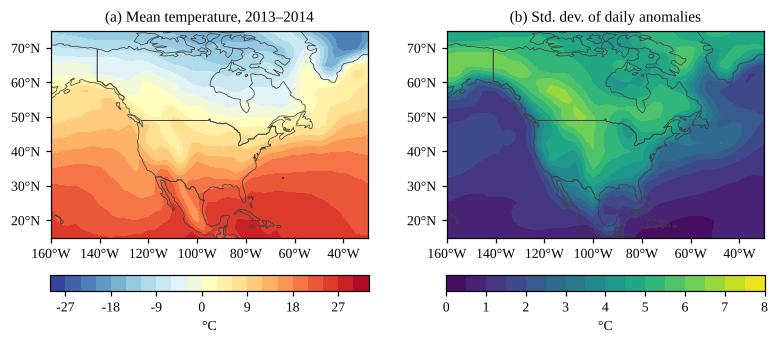

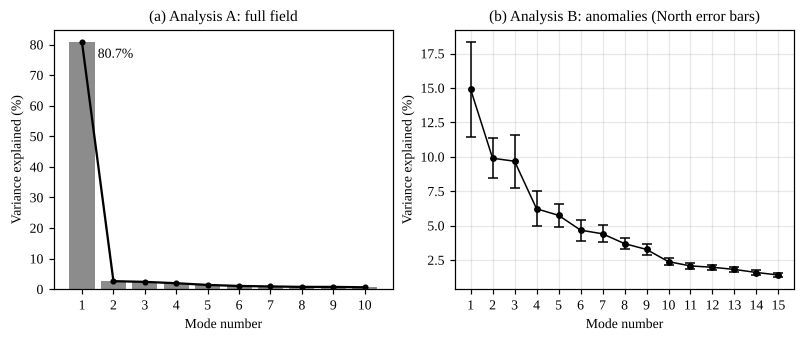

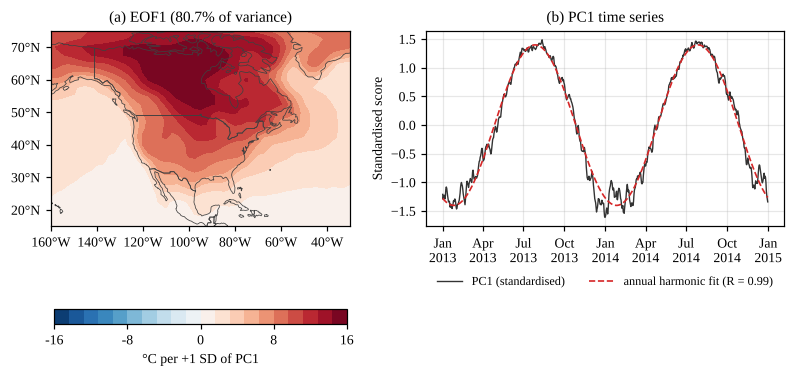

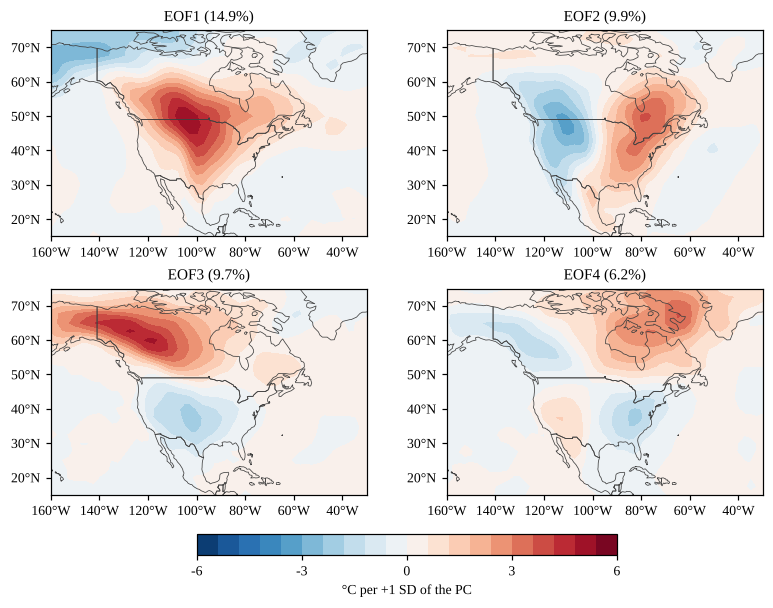

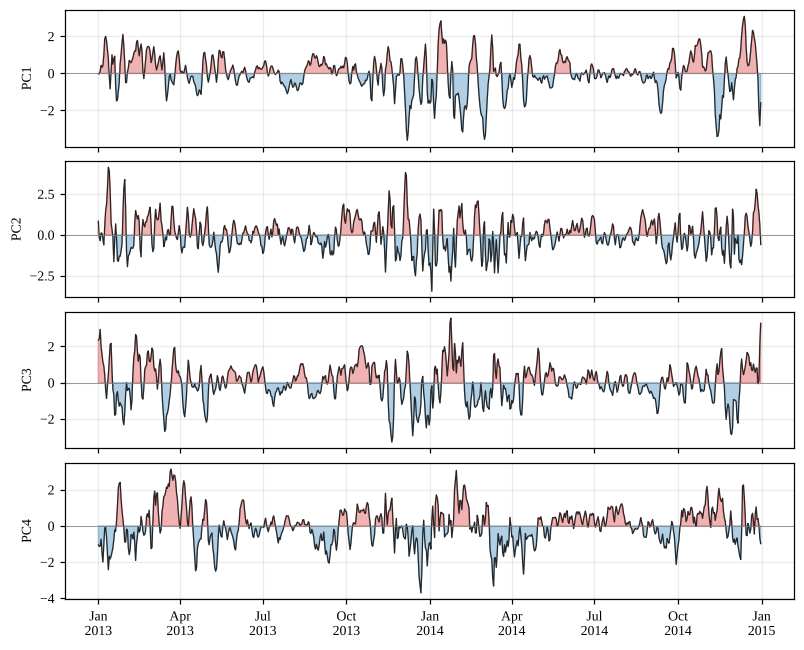

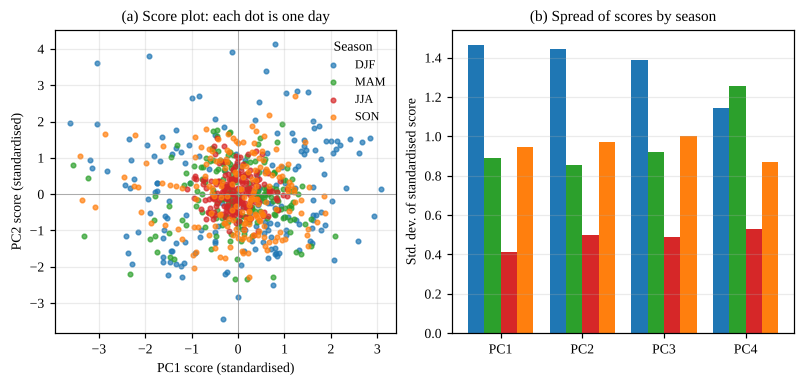

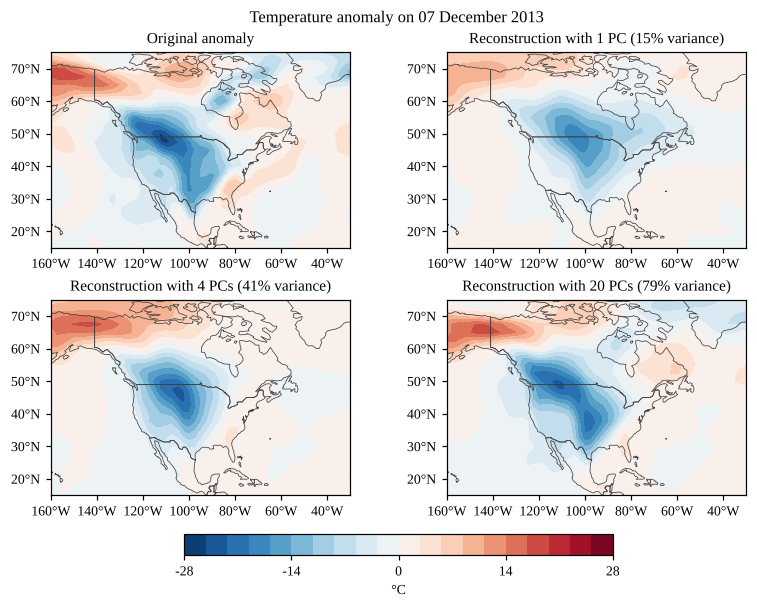

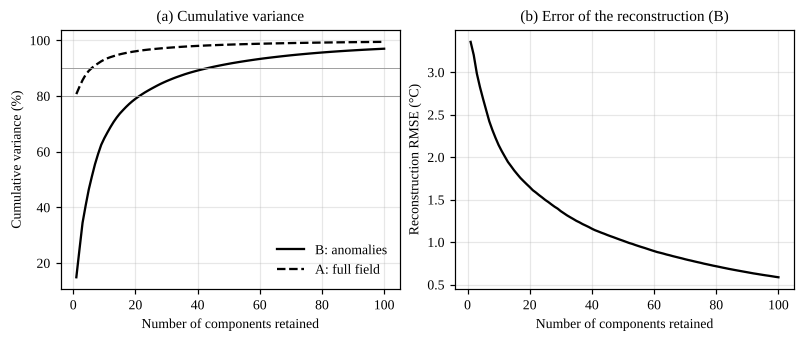

In [11]:
# Figures 1-8 (map helpers first, then each figure is drawn and saved)
import matplotlib.dates as mdates

try:
    geo = json.load(open(get_file("countries.geo.json", GEO_URL)))
    lines = []
    for feat in geo["features"]:
        g = feat["geometry"]
        polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for poly in polys:
            for ring in poly:
                a = np.array(ring)
                a[:, 0] = np.where(a[:, 0] < 0, a[:, 0] + 360, a[:, 0])
                lines.append(a)
except Exception as err:
    print("Coastlines unavailable:", err)
    lines = []

DEG_C = "\u00b0C"

def base_map(ax):
    for a in lines:
        if np.abs(np.diff(a[:, 0])).max() < 180:
            ax.plot(a[:, 0], a[:, 1], color="0.25", lw=0.5)
    ax.set_xlim(lon.min(), lon.max())
    ax.set_ylim(lat.min(), lat.max())
    ax.set_aspect(1 / np.cos(np.deg2rad(45)))
    ax.set_xticks([200, 220, 240, 260, 280, 300, 320])
    ax.set_xticklabels([f"{360 - x}\u00b0W" for x in (200, 220, 240, 260, 280, 300, 320)])
    ax.set_yticks([20, 30, 40, 50, 60, 70])
    ax.set_yticklabels([f"{y}\u00b0N" for y in (20, 30, 40, 50, 60, 70)])

def nice_limit(m):
    step = 0.5 if m < 5 else 1 if m < 10 else 2 if m < 20 else 4
    return float(np.ceil(m / step) * step)

def show_map(ax, data, cmap, sym=False, vmax=None, levels=None):
    if sym:
        m = nice_limit(np.abs(data).max() if vmax is None else vmax)
        cf = ax.contourf(lon, lat, data, levels=np.linspace(-m, m, 21), cmap=cmap,
                         norm=TwoSlopeNorm(vcenter=0, vmin=-m, vmax=m))
        cf.ticks = np.linspace(-m, m, 5)
    else:
        cf = ax.contourf(lon, lat, data, levels=levels, cmap=cmap)
        cf.ticks = None
    base_map(ax)
    return cf

def add_cbar(fig, cf, ax, label, **kw):
    cb = fig.colorbar(cf, ax=ax, orientation="horizontal", pad=0.06, label=label, format="%g", **kw)
    if cf.ticks is not None:
        cb.set_ticks(cf.ticks)
    return cb

def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True)
cf = show_map(axs[0], clim_mean, "RdYlBu_r", levels=np.arange(-30, 36, 3))
add_cbar(fig, cf, axs[0], DEG_C, shrink=0.9)
axs[0].set_title("(a) Mean temperature, 2013\u20132014")
cf = show_map(axs[1], anom.std(0), "viridis", levels=np.arange(0, 8.5, 0.5))
add_cbar(fig, cf, axs[1], DEG_C, shrink=0.9)
axs[1].set_title("(b) Std. dev. of daily anomalies")
fig.savefig(FIG_DIR / "fig1_climatology_and_variability.png")

fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True)
m = np.arange(1, 11)
axs[0].bar(m, varA[:10], color="0.55")
axs[0].plot(m, varA[:10], "ko-", ms=3)
axs[0].set_title("(a) Analysis A: full field")
axs[0].set_xlabel("Mode number")
axs[0].set_ylabel("Variance explained (%)")
axs[0].set_xticks(m)
axs[0].text(1.5, varA[0] - 5, f"{varA[0]:.1f}%", fontsize=9)
m = np.arange(1, K + 1)
axs[1].errorbar(m, varB[:K], yerr=100 * errB / lamB.sum(), fmt="ko-", ms=3.5, capsize=3, lw=1)
axs[1].set_title("(b) Analysis B: anomalies (North error bars)")
axs[1].set_xlabel("Mode number")
axs[1].set_ylabel("Variance explained (%)")
axs[1].set_xticks(m)
axs[1].grid(alpha=0.3)
fig.savefig(FIG_DIR / "fig2_scree_plots.png")

fig = plt.figure(figsize=(7.2, 3.3), constrained_layout=True)
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.1])
ax = fig.add_subplot(gs[0])
cf = show_map(ax, regA[0], "RdBu_r", sym=True)
add_cbar(fig, cf, ax, f"{DEG_C} per +1 SD of PC1", shrink=0.9)
ax.set_title(f"(a) EOF1 ({varA[0]:.1f}% of variance)")
ax = fig.add_subplot(gs[1])
ax.plot(time, zA[:, 0], color="0.2", lw=0.9, label="PC1 (standardised)")
ax.plot(time, fit1, color="tab:red", lw=1.1, ls="--", label=f"annual harmonic fit (R = {R_annual:.2f})")
ax.set_title("(b) PC1 time series")
ax.set_ylabel("Standardised score")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
date_axis(ax)
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "fig3_analysisA_EOF1_PC1.png")

fig, axs = plt.subplots(2, 2, figsize=(7.2, 5.4), constrained_layout=True)
vm = np.abs(regB[:4]).max()
for k, ax in enumerate(axs.ravel()):
    cf = show_map(ax, regB[k], "RdBu_r", sym=True, vmax=vm)
    ax.set_title(f"EOF{k + 1} ({varB[k]:.1f}%)")
cb = fig.colorbar(cf, ax=axs, orientation="horizontal", pad=0.03, shrink=0.55, format="%g",
                  label=f"{DEG_C} per +1 SD of the PC")
cb.set_ticks(cf.ticks)
fig.savefig(FIG_DIR / "fig4_analysisB_EOF1to4.png")

fig, axs = plt.subplots(4, 1, figsize=(7.2, 5.8), sharex=True, constrained_layout=True)
for k, ax in enumerate(axs):
    ax.plot(time, zB[:, k], color="0.15", lw=0.8)
    ax.axhline(0, color="0.5", lw=0.5)
    ax.fill_between(time, 0, zB[:, k], where=zB[:, k] > 0, color="tab:red", alpha=0.35)
    ax.fill_between(time, 0, zB[:, k], where=zB[:, k] < 0, color="tab:blue", alpha=0.35)
    ax.set_ylabel(f"PC{k + 1}")
    ax.grid(alpha=0.25)
date_axis(axs[-1])
fig.savefig(FIG_DIR / "fig5_analysisB_PC1to4.png")

season = np.array([{12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM", 6: "JJA", 7: "JJA", 8: "JJA",
                    9: "SON", 10: "SON", 11: "SON"}[mth] for mth in time.month])
cols = {"DJF": "tab:blue", "MAM": "tab:green", "JJA": "tab:red", "SON": "tab:orange"}
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.4), constrained_layout=True)
for s_, c in cols.items():
    sel = season == s_
    axs[0].scatter(zB[sel, 0], zB[sel, 1], s=9, color=c, alpha=0.7, label=s_)
axs[0].axhline(0, color="0.6", lw=0.5)
axs[0].axvline(0, color="0.6", lw=0.5)
axs[0].set_xlabel("PC1 score (standardised)")
axs[0].set_ylabel("PC2 score (standardised)")
axs[0].set_title("(a) Score plot: each dot is one day")
axs[0].legend(frameon=False, title="Season", fontsize=8)
axs[0].grid(alpha=0.25)
bw = 0.2
for j, (s_, c) in enumerate(cols.items()):
    axs[1].bar(np.arange(4) + (j - 1.5) * bw, [zB[season == s_, k].std() for k in range(4)], bw, color=c, label=s_)
axs[1].set_xticks(np.arange(4))
axs[1].set_xticklabels([f"PC{k + 1}" for k in range(4)])
axs[1].set_ylabel("Std. dev. of standardised score")
axs[1].set_title("(b) Spread of scores by season")
axs[1].grid(alpha=0.25, axis="y")
fig.savefig(FIG_DIR / "fig6_score_plots.png")

i_ex = int(np.argmax(np.abs(zB[:, 0])))
ex_date = time[i_ex]
print("Example day (largest |PC1|):", ex_date.date())
orig = anom[i_ex] - anom.mean(0)
fig, axs = plt.subplots(2, 2, figsize=(7.2, 5.2), constrained_layout=True)
vm = np.abs(orig).max()
for ax, (lab, kk) in zip(axs.ravel(), [("Original anomaly", None), ("1 PC", 1), ("4 PCs", 4), ("20 PCs", 20)]):
    d = orig if kk is None else (pcB[i_ex:i_ex + 1, :kk] @ eofB[:kk]).reshape(ny, nx) / w
    cf = show_map(ax, d, "RdBu_r", sym=True, vmax=vm)
    ax.set_title(lab if kk is None else f"Reconstruction with {lab} ({cumB[kk - 1]:.0f}% variance)")
cb = fig.colorbar(cf, ax=axs, orientation="horizontal", pad=0.03, shrink=0.55, format="%g", label=DEG_C)
cb.set_ticks(cf.ticks)
fig.suptitle(f"Temperature anomaly on {ex_date:%d %B %Y}", y=1.03)
fig.savefig(FIG_DIR / "fig7_reconstruction_example.png")

fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True)
mm = np.arange(1, 101)
axs[0].plot(mm, np.cumsum(varB)[:100], "k-", label="B: anomalies")
axs[0].plot(mm, np.cumsum(varA)[:100], "k--", label="A: full field")
for pct in (80, 90):
    axs[0].axhline(pct, color="0.6", lw=0.6)
axs[0].set_xlabel("Number of components retained")
axs[0].set_ylabel("Cumulative variance (%)")
axs[0].set_title("(a) Cumulative variance")
axs[0].legend(frameon=False, loc="lower right")
axs[0].grid(alpha=0.3)
axs[1].plot(mm, rmse_all, "k-")
axs[1].set_xlabel("Number of components retained")
axs[1].set_ylabel(f"Reconstruction RMSE ({DEG_C})")
axs[1].set_title("(b) Error of the reconstruction (B)")
axs[1].grid(alpha=0.3)
fig.savefig(FIG_DIR / "fig8_cumulative_variance_and_rmse.png")
plt.show()

## 10. Save results

Collects every number quoted in the report into `outputs/results_summary.json` so that each value in the text can be traced back to this notebook.

In [12]:
# Write the numbers used in the report to results_summary.json
extremes = {}
for k in range(4):
    i_max, i_min = int(np.argmax(zB[:, k])), int(np.argmin(zB[:, k]))
    extremes[f"PC{k + 1}"] = {"max_date": str(time[i_max].date()), "max_val": float(zB[i_max, k]),
                              "min_date": str(time[i_min].date()), "min_val": float(zB[i_min, k])}

def season_std(k):
    return {s: float(zB[season == s, k].std()) for s in cols}

summary = {
    "n_days": n, "n_points": p, "n_lat": ny, "n_lon": nx,
    "mean_temp_degC": float(clim_mean.mean()), "min_clim": float(clim_mean.min()), "max_clim": float(clim_mean.max()),
    "seasonal_share_pct": float(seasonal_share),
    "A": {"var": varA[:10].tolist(), "eig": lamA[:10].tolist(), "R_annual": float(R_annual), "peak_doy": peak_doy,
          "total_var": float(lamA.sum()), "lag1_pc1": float(r1A[0]),
          "n_nonzero": int(np.sum(lamA > 1e-10 * lamA[0]))},
    "B": {"var": varB[:15].tolist(), "eig": lamB[:15].tolist(), "cum": cumB[:15].tolist(),
          "total_var": float(lamB.sum()), "n_for": n_for, "std_anom": float(std_anom),
          "r1": r1B.tolist(), "neff": neffB.tolist(), "err": errB.tolist(), "sep": [bool(s) for s in sep]},
    "checks": checks, "extremes": extremes, "example_day": str(ex_date.date()),
    "season_std_pc1": season_std(0), "season_std_pc2": season_std(1),
    "season_std_pc3": season_std(2), "season_std_pc4": season_std(3),
    "rmse_k": {int(r["k"]): float(r["RMSE (degC)"]) for r in rec_rows},
    "std_by_season": {s: float(anom[season == s].std()) for s in cols},
    "worked": worked, "pcA_harmonic_R": pcA_fit, "pattern_corr": pat.round(3).to_dict(),
}
def peak(m):
    i, j = np.unravel_index(np.argmax(np.abs(m)), m.shape)
    return {"lat": float(lat[i]), "lon": float(lon[j]), "value": float(m[i, j])}

summary["peaks"] = {
    "A_EOF1": peak(regA[0]), "A_EOF1_min": float(regA[0].min()), "A_EOF1_max": float(regA[0].max()),
    "A_EOF1_min_loc": [float(lat[np.unravel_index(np.argmin(regA[0]), regA[0].shape)[0]]),
                       float(lon[np.unravel_index(np.argmin(regA[0]), regA[0].shape)[1]])],
    "A_EOF1_mean_south_of_25N": float(regA[0][lat <= 25].mean()),
    "A_EOF1_mean_north_of_55N": float(regA[0][lat >= 55].mean()),
    "B_EOF": {f"EOF{k + 1}": peak(regB[k]) for k in range(4)},
    "B_EOF_min_max": {f"EOF{k + 1}": [float(regB[k].min()), float(regB[k].max())] for k in range(4)},
    "B_std_max": peak(anom.std(0)),
}
with open("outputs/results_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved figures to", FIG_DIR, "tables to", TAB_DIR)

Saved figures to outputs/figures tables to outputs/tables
